Cell 1 — Install and import libraries

In [4]:
!pip -q install tensorflow-datasets scikit-learn matplotlib seaborn importlib-resources

Cell 2 — Import libraries

In [2]:
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


Load the PlantVillage dataset

In [5]:
(ds_train, ds_test), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

class_names = info.features["label"].names
num_classes = len(class_names)

print("Number of classes:", num_classes)
print("Class names:", class_names)
print("Training images:", info.splits["train"].num_examples * 0.8)
print("Testing images:", info.splits["train"].num_examples * 0.2)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.74SIXV_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Number of classes: 38
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight'

Preprocess images

In [6]:
IMG_SIZE = 160
BATCH_SIZE = 32

def preprocess_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

train_ds = (
    ds_train
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    ds_test
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Image preprocessing completed.")

Image preprocessing completed.


Display sample images

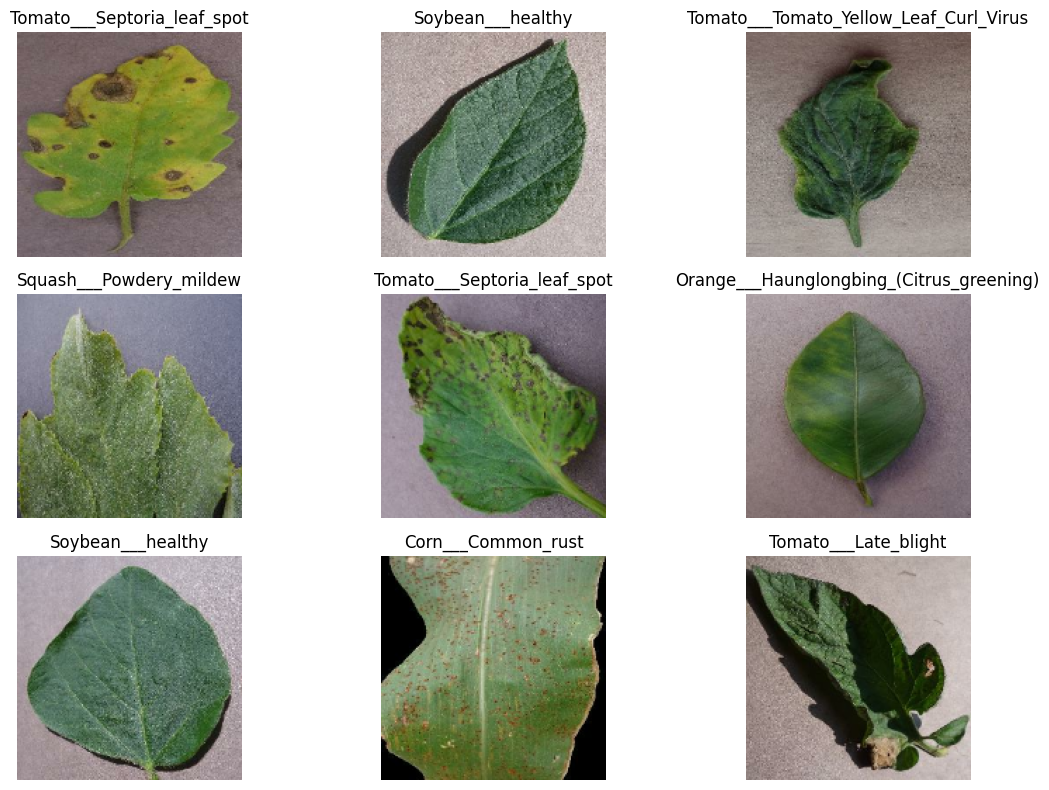

In [7]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        # Convert MobileNetV2-preprocessed pixels back approximately
        # to the 0–1 range for display.
        display_image = images[i].numpy() / 2.0 + 0.5
        plt.imshow(np.clip(display_image, 0, 1))

        label_id = int(labels[i].numpy())
        plt.title(class_names[label_id])
        plt.axis("off")

plt.tight_layout()
plt.show()

Build the MobileNetV2 model

In [8]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Train the model

In [9]:
EPOCHS = 3

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS
)

Epoch 1/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1121s 818ms/step - accuracy: 0.8673 - loss: 0.4635 - val_accuracy: 0.9421 - val_loss: 0.1825
Epoch 2/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1166s 857ms/step - accuracy: 0.9394 - loss: 0.1914 - val_accuracy: 0.9508 - val_loss: 0.1517
Epoch 3/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1042s 767ms/step - accuracy: 0.9490 - loss: 0.1563 - val_accuracy: 0.9537 - val_loss: 0.1364


Plot accuracy and loss

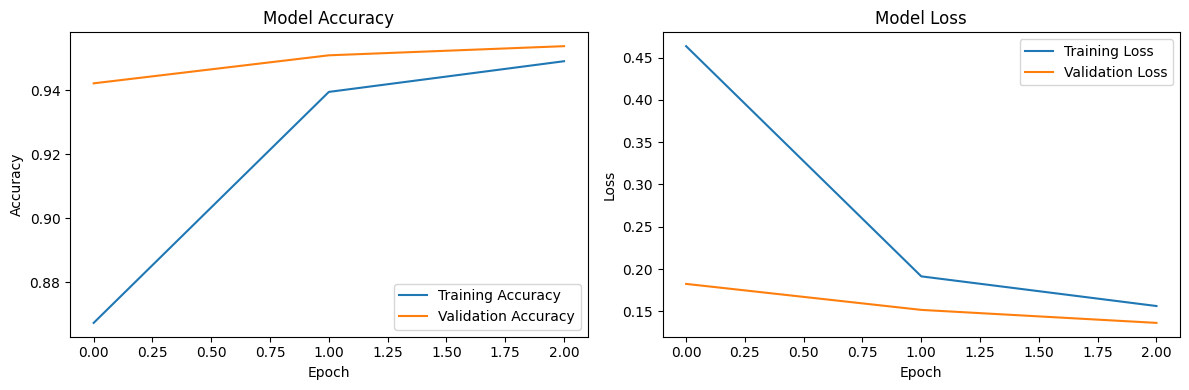

In [10]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Evaluate the model

In [11]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

340/340 ━━━━━━━━━━━━━━━━━━━━ 204s 601ms/step - accuracy: 0.9537 - loss: 0.1364
Test Accuracy: 95.37%
Test Loss: 0.1364


Classification report and confusion matrix

340/340 ━━━━━━━━━━━━━━━━━━━━ 200s 579ms/step
Classification Report:

                                               precision    recall  f1-score   support

                           Apple___Apple_scab       0.91      0.90      0.90       129
                            Apple___Black_rot       1.00      0.95      0.97       154
                     Apple___Cedar_apple_rust       0.98      0.94      0.96        54
                              Apple___healthy       0.97      0.99      0.98       339
                          Blueberry___healthy       0.98      1.00      0.99       292
                             Cherry___healthy       0.99      0.98      0.99       195
                      Cherry___Powdery_mildew       0.99      0.97      0.98       201
   Corn___Cercospora_leaf_spot Gray_leaf_spot       0.77      0.88      0.82       108
                           Corn___Common_rust       1.00      0.99      0.99       239
                               Corn___healthy       1.00    

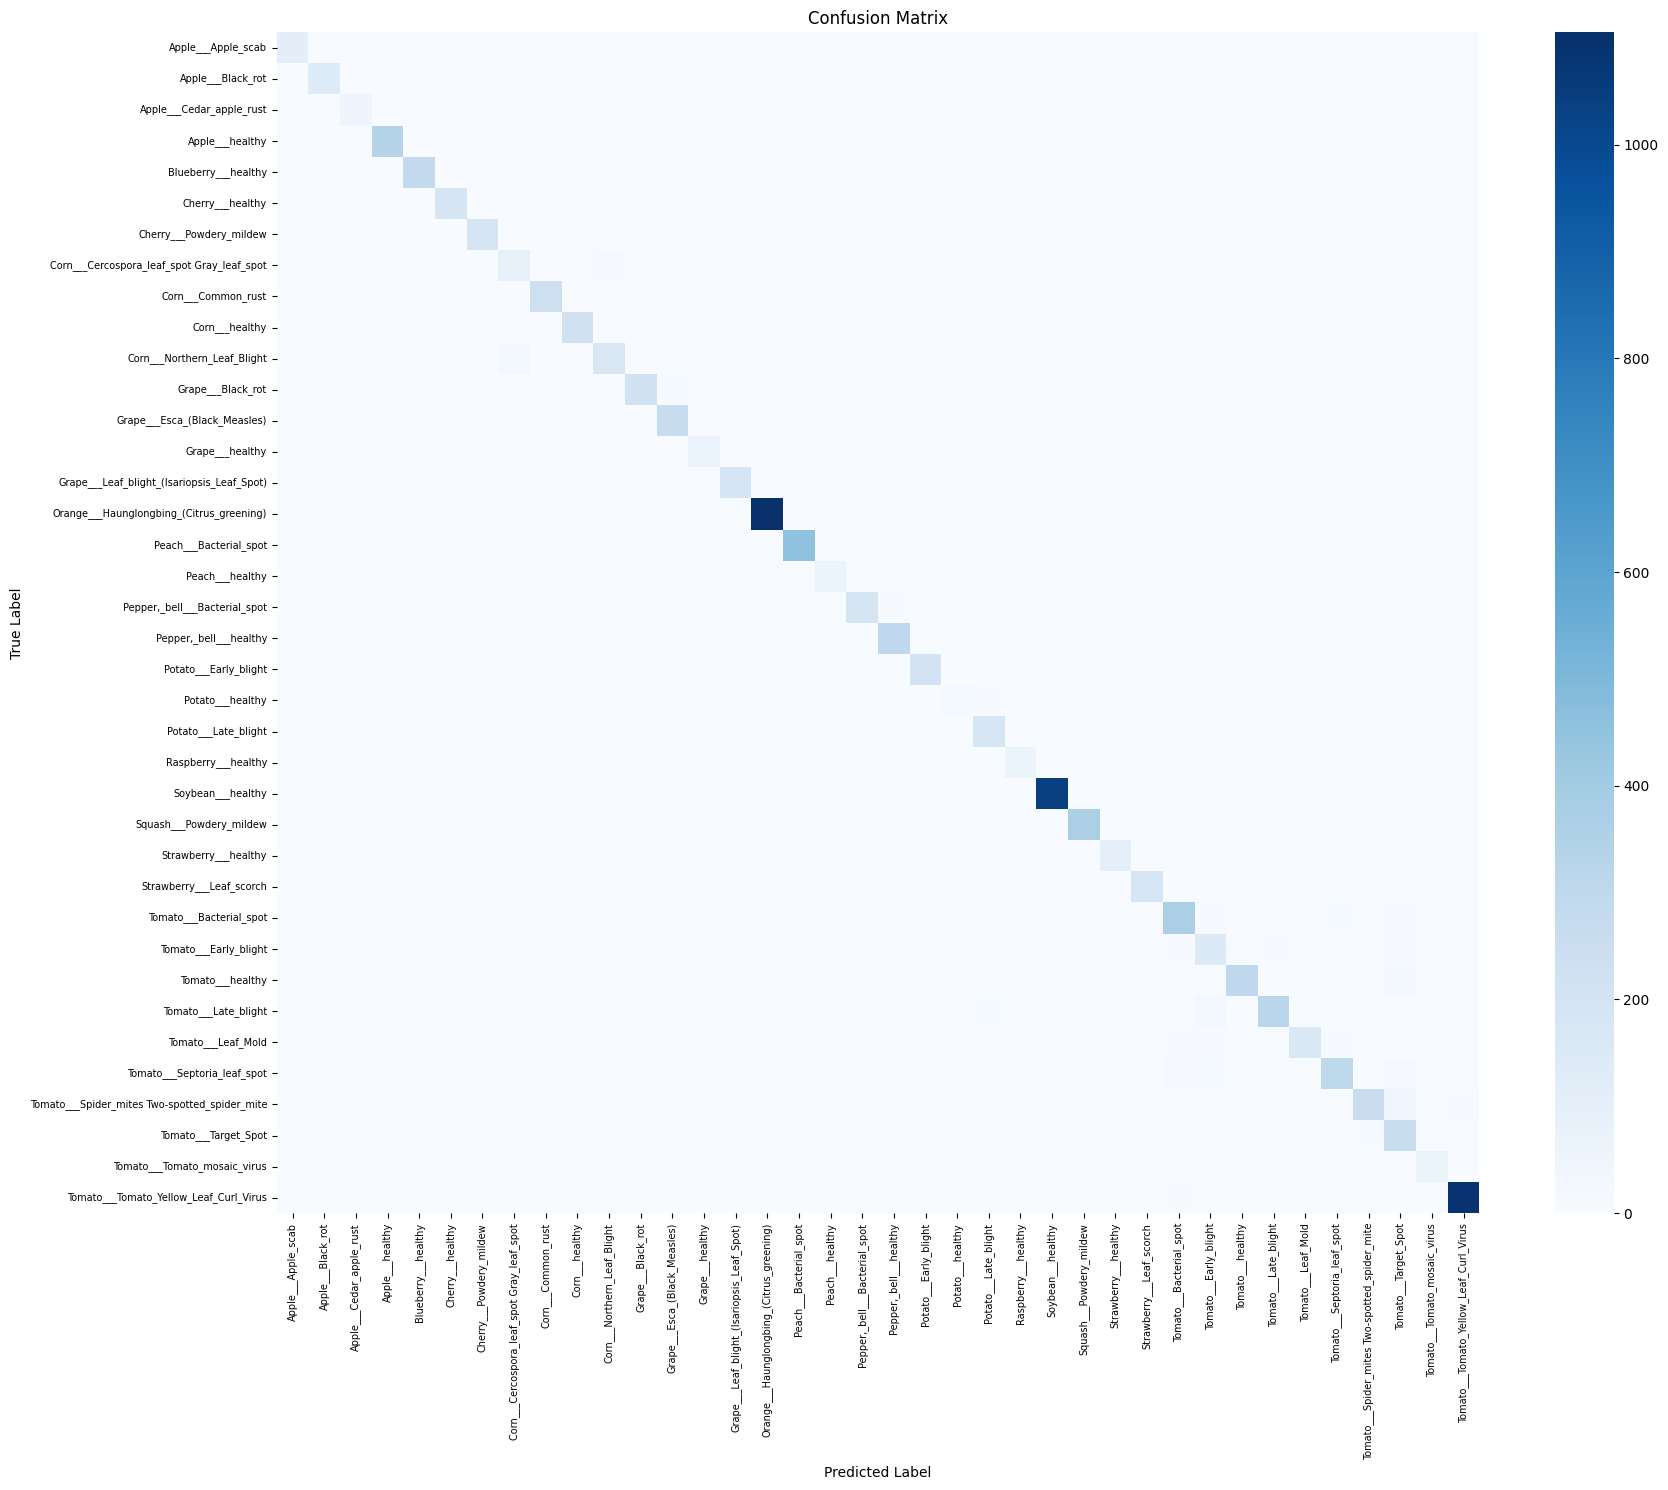

In [12]:
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("Classification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

Show a prediction

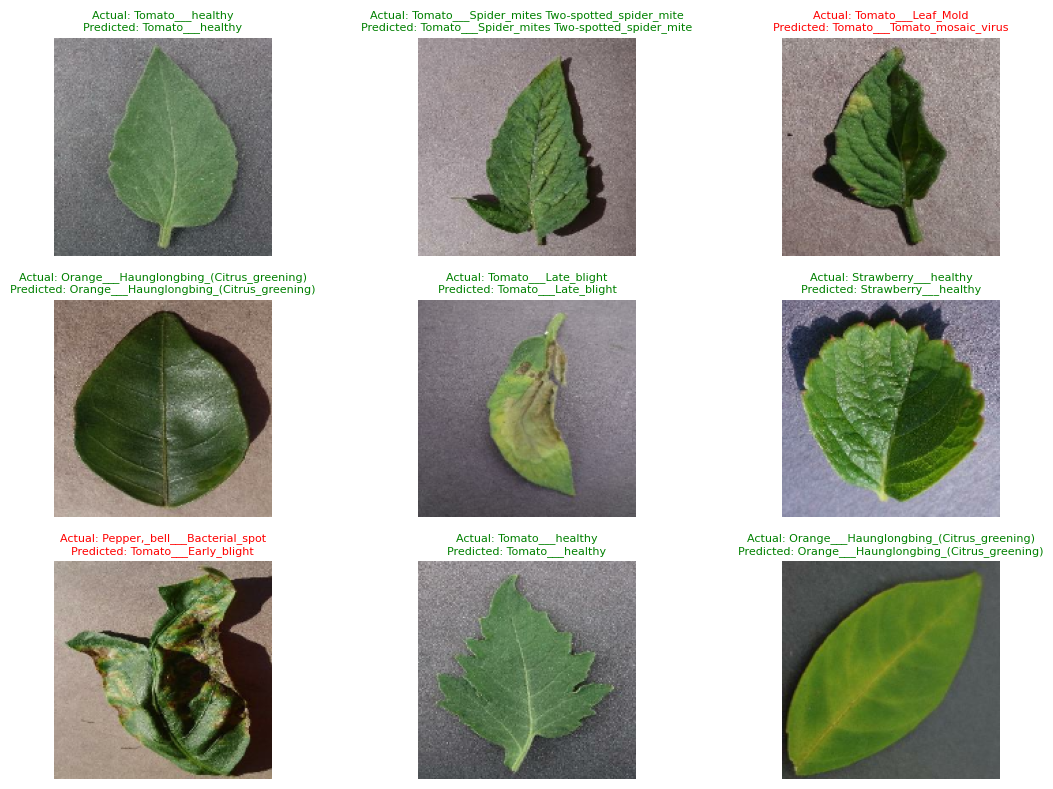

In [13]:
for images, labels in test_ds.take(1):
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 8))

    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)

        display_image = images[i].numpy() / 2.0 + 0.5
        plt.imshow(np.clip(display_image, 0, 1))

        actual = class_names[int(labels[i].numpy())]
        predicted = class_names[int(np.argmax(predictions[i]))]

        color = "green" if actual == predicted else "red"
        plt.title(
            f"Actual: {actual}\nPredicted: {predicted}",
            color=color,
            fontsize=8
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

Grad-CAM explainability

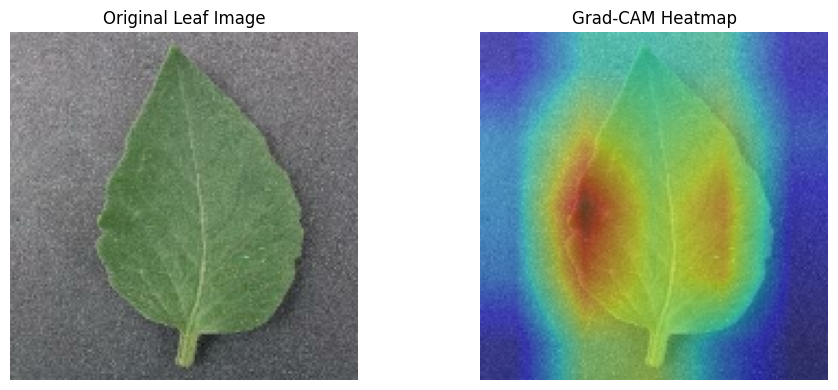

In [19]:
def make_gradcam_heatmap(image_batch, model, base_model):
    # Programmatically find the last 4D convolution/activation layer in MobileNetV2
    last_conv_layer = None
    for layer in reversed(base_model.layers):
        try:
            if len(layer.output.shape) == 4:
                last_conv_layer = layer
                break
        except (AttributeError, ValueError):
            continue

    if last_conv_layer is None:
        raise ValueError("Could not find a 4D convolutional/activation layer in the base model.")

    # To avoid nested graph issues, we construct the grad_model entirely relative to base_model
    grad_model = tf.keras.Model(
        inputs=base_model.inputs,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_predictions = grad_model(
            image_batch, training=False
        )

        # Reconstruct the classification head output using base_model's outputs
        # Our classification head consists of: GlobalAveragePooling2D -> Dropout -> Dense(softmax)
        x = tf.keras.layers.GlobalAveragePooling2D()(base_predictions)
        # We skip Dropout during inference (training=False)
        # Find the Dense layer in the outer model to get the correct weights
        dense_layer = model.layers[-1]
        predictions = dense_layer(x)

        class_index = tf.argmax(predictions[0])
        class_score = predictions[:, class_index]

    grads = tape.gradient(class_score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return heatmap.numpy()

for images, labels in test_ds.take(1):
    image_batch = images[0:1]

    heatmap = make_gradcam_heatmap(
        image_batch, model, base_model
    )

    original = image_batch[0].numpy() / 2.0 + 0.5
    original = np.clip(original, 0, 1)

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (IMG_SIZE, IMG_SIZE)
    ).numpy().squeeze()

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original Leaf Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(original)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.45)
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

Save your model and results

In [20]:
model.save("crop_disease_mobilenetv2.keras")

results = pd.DataFrame({
    "Metric": ["Test Accuracy (%)", "Test Loss", "Epochs Completed"],
    "Value": [
        round(test_accuracy * 100, 2),
        round(float(test_loss), 4),
        len(history.history["loss"])
    ]
})

results.to_csv("crop_disease_results.csv", index=False)

print(results)
print("\nModel and results saved successfully.")

              Metric    Value
0  Test Accuracy (%)  95.3700
1          Test Loss   0.1364
2   Epochs Completed   3.0000

Model and results saved successfully.


In [21]:
correct = int(np.sum(y_true == y_pred))
incorrect = int(np.sum(y_true != y_pred))

print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Total test examples:", len(y_true))

Correct predictions: 10358
Incorrect predictions: 503
Total test examples: 10861
